In [3]:
import matplotlib
from datascience import *
%matplotlib inline
import matplotlib.pyplot as plots
import numpy as np
plots.style.use('fivethirtyeight')

## Mean ##

In [4]:
values = make_array(2, 3, 3, 9)
values

array([2, 3, 3, 9])

The mean (or average) of an array is defined to be the sum of all the values in the array
divided by the size of the array.

In [5]:
sum(values)/len(values)

4.25

In [6]:
# The calculation is built into the np package.
values_mean = np.mean(values)
values_mean

4.25

# Mean as Smoothing the Data

In [7]:
sum(values)

17

In [8]:
# If every item in the array was replaced by the mean, the sum would stay the same.
values2 = make_array(4.25, 4.25, 4.25, 4.25)
sum(values2)

17.0

# Mean as Center of Gravity

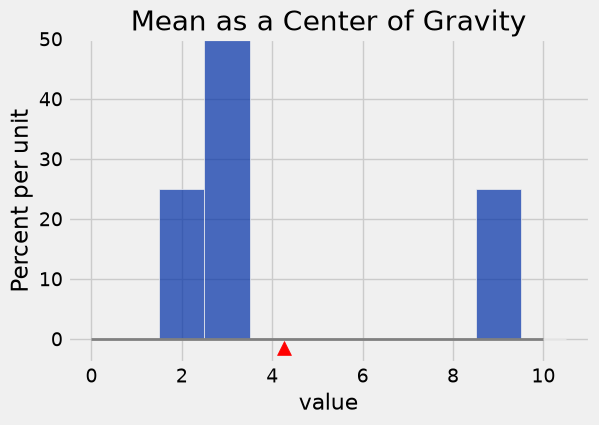

In [9]:
values_table = Table().with_columns('value', values)
values_table
bins_for_display = np.arange(0.5, 10.6, 1)
values_table.hist('value', bins = bins_for_display)
plots.ylim(-0.04, 0.5)
plots.plot([0, 10], [0, 0], color='grey', lw=2)
plots.scatter(4.25, -0.015, marker='^', color='red', s=100)
plots.title('Mean as a Center of Gravity');

The average is located at the point that would balance the data if it was a lever with masses.

Contrast this with the median, which merely splits the data set into two roughly equal halves.

In [10]:
np.median(values)

3.0

## Standard Deviation ##

Standard deviation is a measure of how spread out the data is.

Small standard deviation means the data is tightly clustered around the mean.

The larger the standard deviation, the less tight the clustering.

# Computing the Standard Deviation

Step 1. For each value in the array, compute the "mean minus value".

Step 2. Square the results found in Step 1.

Step 3. Average the squared differences from Step 2.

Step 4. Compute the square root of the average in Step 3.

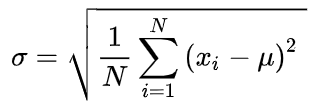

In [11]:
values_table

value
2
3
3
9


## Practice

Step 1: Attach a column that shows "mean minus value".

In [26]:
mean_minus_value = values-values_mean
new = values_table.with_column('mean minus value', mean_minus_value)
new

value,mean minus value
2,-2.25
3,-1.25
3,-1.25
9,4.75


Step 2: Attach a column that shows the squared difference for each row.

In [27]:
squared = (mean_minus_value)**2
squared_tbl = new.with_column('squared', squared)
squared_tbl

value,mean minus value,squared
2,-2.25,5.0625
3,-1.25,1.5625
3,-1.25,1.5625
9,4.75,22.5625


Step 3: Compute the average of the squared difference column. (No need to attach to table.)

In [28]:
average = np.average(squared)
average

7.6875

Step 4: Compute the square root of the sum from Step 3.

In [29]:
np.sqrt(average)

2.7726341266023544

Or just use the built-in function...

In [30]:
np.std(values)

2.7726341266023544

Modify the values of the array to see the effect on the mean and standard deviation. 

In [34]:
values

array([2, 3, 3, 9])

In [31]:
print(np.mean(values))
print(np.std(values))

4.25
2.7726341266


In [32]:
# Same mean but smaller standadrd deviation
values2 = make_array(4, 3, 3, 7)
print(np.mean(values2))
print(np.std(values2))

4.25
1.63935963108


In [33]:
# Same mean but bigger standard deviation (moved values farther away)
values3 = make_array(0, 2, 4, 11)
print(np.mean(values3))
print(np.std(values3))

4.25
4.14578098794
